# Myocardial Diffusion Model

## Setup

This project requires Python 3.7 or above:

In [1]:
import sys
assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [2]:
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

**Warning**: the latest TensorFlow versions are based on Keras 3. Unfortunately it's much harder for this, in particular adding custom losses using the functional API is not implemented yet. So for this Model I've had to revert to Keras 2. To do that, I set the `TF_USE_LEGACY_KERAS` environment variable to `"1"` and import the `tf_keras` package. This ensures that `tf.keras` points to `tf_keras`, which is Keras 2.*.

In [3]:
import importlib
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras

I0000 00:00:1792088300.299807   74096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792088300.336233   74096 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792088301.693659   74096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


And TensorFlow ≥ 2.8:

In [4]:
import tensorflow as tf
assert version.parse(tf.__version__) >= version.parse("2.8.0")

Let's define the default font sizes to make the figures prettier:

In [5]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/generative` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the report:

In [6]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "generative"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=256):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

This chapter can be very slow without a GPU, so let's make sure there's one, or else issue a warning:

In [7]:
import sys, os
print("Python Executable:", sys.executable)
print("Platform:", sys.platform)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH", "NOT SET"))

Python Executable: /home/molham/miniconda3/envs/myocardial-gdm/bin/python
Platform: linux
LD_LIBRARY_PATH: /usr/lib/wsl/lib:/home/molham/miniconda3/envs/myocardial-gdm/lib/python3.10/site-packages/tensorflow:


In [8]:
if not tf.config.list_physical_devices('GPU'):
    print("No GPU was detected. Neural nets can be very slow without a GPU.")
    if "google.colab" in sys.modules:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if "kaggle_secrets" in sys.modules:
        print("Go to Settings > Accelerator and select GPU.")
else:
    print("GPU detected. You are good to go!")

GPU detected. You are good to go!


## MyoPS data and plotting setup

Use only the still 3D volumes in `MyoPS_train` and `MyoPS_val`; pair LGE with the available C0 (static bSSFP) or T2 target within each case. Cases missing a target are excluded from that modality's supervised loss but can still be used for inference.


In [9]:
import os
import sys
import numpy as np
from pathlib import Path

module_dir = next(
    (path.resolve() for path in
     (Path.cwd(), Path.cwd() / "myocardial-gdm", Path.cwd().parent / "myocardial-gdm")
     if (path / "myocardial_data.py").is_file()),
    None,
)
if module_dir is None:
    raise FileNotFoundError("Could not locate myocardial_data.py")
sys.path.insert(0, str(module_dir))
import myocardial_data
importlib.reload(myocardial_data)

from myocardial_data import (
    TARGET_MODALITIES,
    build_conditional_diffusion_model,
    find_paired_cases,
    generate_conditioned,
    load_aligned_pair,
    load_lge_volume,
    make_paired_dataset,
    paired_case_counts,
    synthesize_volume,
)

data_root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
if os.environ.get("MYO_DATA_ROOT"):
    data_root_candidates.insert(0, Path(os.environ["MYO_DATA_ROOT"]).expanduser())
DATA_ROOT = next(
    (path.resolve() for path in data_root_candidates
     if (path / "Myo_train" / "MyoPS_train").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Set MYO_DATA_ROOT to the directory containing Myo_train and Myo_val"
    )

TRAIN_PAIRS = find_paired_cases(DATA_ROOT / "Myo_train" / "MyoPS_train")
VALID_PAIRS = find_paired_cases(DATA_ROOT / "Myo_val" / "MyoPS_val")
print("Training paired cases:", dict(paired_case_counts(TRAIN_PAIRS)))
print("Validation paired cases:", dict(paired_case_counts(VALID_PAIRS)))

def plot_multiple_images(images, n_cols=8):
    images = np.asarray(images)
    if images.ndim == 4 and images.shape[-1] == 1:
        images = images[..., 0]
    n_images = len(images)
    n_rows = (n_images - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * 1.5, n_rows * 1.5))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="gray", vmin=-1, vmax=1)
        plt.axis("off")


Training paired cases: {'C0': 104, 'T2': 80}
Validation paired cases: {'C0': 15, 'T2': 15}


# Diffusion Models

For each paired training slice, the forward diffusion process adds Gaussian noise to the target (C0 or T2) image. The denoiser receives that noisy target, its aligned LGE source slice, the diffusion time, and the requested target modality, then predicts the added noise. This makes generation conditional on both LGE anatomy and whether C0/bSSFP or T2 is requested.

The [DDPM paper](https://arxiv.org/abs/2006.11239) increased $\beta_t$ from $\beta_1$ = 0.0001 to $\beta_T = $0.02 ($T$ is the max step), but the [Improved DDPM paper](https://arxiv.org/pdf/2102.09672.pdf) suggested using the following $\cos^2(\ldots)$ schedule instead, which gradually decreases $\bar{\alpha_t} = \prod_{i=0}^{t} \alpha_i$ from 1 to 0, where $\alpha_t = 1 - \beta_t$:

In [10]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # add α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ , α̅ₜ , βₜ for t = 0 to T

np.random.seed(42)  # extra code – for reproducibility
T = 1000
alpha, alpha_cumprod, beta = variance_schedule(T)

Use $T = 1,000$ for training. The variable `alpha` contains $\alpha_0, ..., \alpha_T$, and `alpha_cumprod` contains $\bar{\alpha_0}, ..., \bar{\alpha_T}$. Synthesis uses 100 deterministic DDIM steps by default rather than evaluating all 1,000 reverse steps.

Let's plot `alpha_cumprod`:

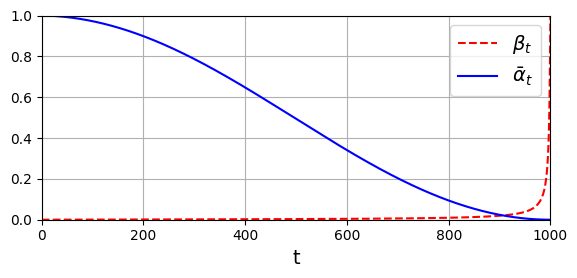

In [11]:
# extra code – this cell generates and saves Figure 17–21
plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1])
plt.grid(True)
plt.xlabel(r"t")
plt.legend()
save_fig("variance_schedule_plot")
plt.show()

The paired input pipeline streams slices from disk and adds noise to each target slice at an independently sampled time between 1 and $T$. It returns the conditional inputs and the noise targets:

* The inputs contain the noisy target, aligned LGE source, time index, and target-modality ID. Noise is added in one step using equation (4) from the DDPM paper.
* The target is the noise that was used to produce the noisy images.

In [12]:
# The paired MyoPS dataset builder adds diffusion noise after resizing paired slices.

Now let's prepare a `tf.data.Dataset` for training, and one for validation.

In [13]:
IMAGE_SIZE = 128
BATCH_SIZE = 16
tf.random.set_seed(43)
train_set = make_paired_dataset(
    TRAIN_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, shuffle=True,
)
valid_set = make_paired_dataset(
    VALID_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

I0000 00:00:1792088302.987456   74096 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9513 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


As a quick sanity check, let's take a look at a few training samples, along with the corresponding noise to predict, and the original images (which we get by subtracting the appropriately scaled noise from the appropriately scaled noisy image):

I0000 00:00:1792088304.031219   74385 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


LGE conditions


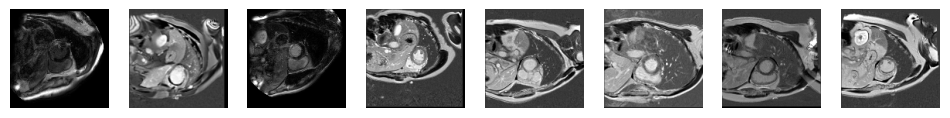

Target modalities: [b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'T2', b'C0 / bSSFP', b'C0 / bSSFP']
Original target images reconstructed from the forward process


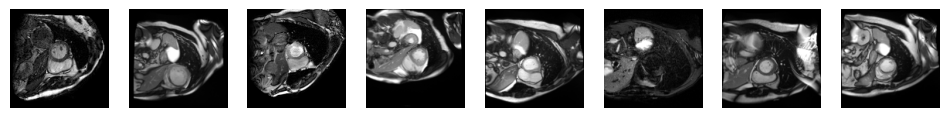

Time steps: [405 312 441 991 443 657 308 151]
Noisy images


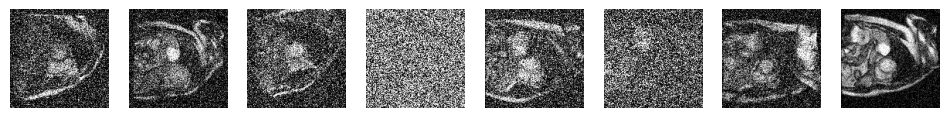

Noise to predict


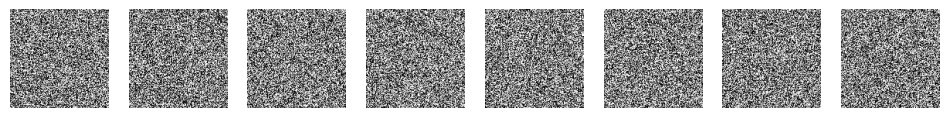

In [14]:
# extra code – just a quick sanity check

def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]  # get the first batch
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("LGE conditions")
plot_multiple_images(X_dict["X_condition"][:8].numpy())
plt.show()
modality_names = tf.gather(tf.constant(["C0 / bSSFP", "T2"]), X_dict["modality"][:8])
print("Target modalities:", modality_names.numpy().tolist())
print("Original target images reconstructed from the forward process")
plot_multiple_images(X_original[:8].numpy())
plt.show()
print("Time steps:", X_dict["time"].numpy()[:8])
print("Noisy images")
plot_multiple_images(X_dict["X_noisy"][:8].numpy())
plt.show()
print("Noise to predict")
plot_multiple_images(Y_noise[:8].numpy())
plt.show()

The U-Net jointly processes the noisy target and the LGE condition. Sinusoidal timestep encodings and a learned C0/T2 modality embedding are injected into its down- and up-sampling blocks.

In [15]:
embed_size = 64

The model predicts noise in a 128 × 128 target slice. It uses the LGE slice as a spatial condition, and a two-entry modality embedding distinguishes C0/bSSFP synthesis from T2 synthesis. The three down/up-sampling stages use skip connections to retain spatial detail.

In [16]:
def build_diffusion_model():
    return build_conditional_diffusion_model(
        timesteps=T, image_size=IMAGE_SIZE, embedding_size=embed_size
    )

Let's train the model!

In [17]:
tf.random.set_seed(42)
model = build_diffusion_model()
model.compile(
    loss=tf.keras.losses.Huber(),
    optimizer=tf.keras.optimizers.Nadam(),
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="noise_mae")],
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "myocardial_conditional_diffusion.keras",
    monitor="val_loss",
    save_best_only=True,
)
training_log_cb = tf.keras.callbacks.CSVLogger(
    "myocardial_training_history.csv", append=False
)

history = model.fit(
    train_set,
    validation_data=valid_set,
    epochs=100,
    callbacks=[checkpoint_cb, training_log_cb],
)

Epoch 1/100


E0000 00:00:1792088313.867144   74096 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape ingradient_tape/huber_loss/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792088320.103056   74318 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792088322.451290   74310 service.cc:153] XLA service 0x756a17ca9cf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792088322.451320   74310 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 SUPER, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792088322.460142   74310 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792088322.565275   74310 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


     56/Unknown - 20s 76ms/step - loss: 0.5305 - noise_mae: 0.8948

I0000 00:00:1792088333.016304   75730 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11707523421724181699
I0000 00:00:1792088333.016347   75730 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 937584363848527734


56/56 [==============================] - 22s 104ms/step - loss: 0.5305 - noise_mae: 0.8948 - val_loss: 0.4407 - val_noise_mae: 0.8166
Epoch 2/100
56/56 [==============================] - 10s 74ms/step - loss: 0.1556 - noise_mae: 0.4365 - val_loss: 0.4218 - val_noise_mae: 0.7945
Epoch 3/100
56/56 [==============================] - 10s 73ms/step - loss: 0.1139 - noise_mae: 0.3619 - val_loss: 0.4014 - val_noise_mae: 0.7705
Epoch 4/100
56/56 [==============================] - 10s 75ms/step - loss: 0.0971 - noise_mae: 0.3276 - val_loss: 0.3705 - val_noise_mae: 0.7335
Epoch 5/100
56/56 [==============================] - 10s 75ms/step - loss: 0.0867 - noise_mae: 0.3052 - val_loss: 0.3227 - val_noise_mae: 0.6750
Epoch 6/100
56/56 [==============================] - 11s 77ms/step - loss: 0.0796 - noise_mae: 0.2885 - val_loss: 0.2565 - val_noise_mae: 0.5894
Epoch 7/100
56/56 [==============================] - 10s 73ms/step - loss: 0.0747 - noise_mae: 0.2768 - val_loss: 0.1928 - val_noise_mae: 0.4

### Training results

Compare training and validation noise-prediction loss and MAE across epochs. MAE is used instead of classification accuracy because the denoiser predicts continuous-valued noise.


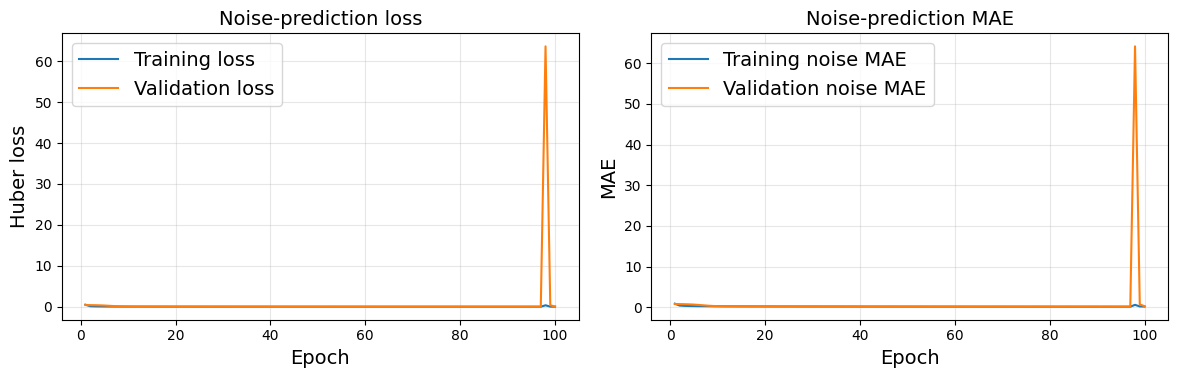

In [18]:
epochs = np.arange(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history.history["loss"], label="Training loss")
axes[0].plot(epochs, history.history["val_loss"], label="Validation loss")
axes[0].set(title="Noise-prediction loss", xlabel="Epoch", ylabel="Huber loss")
axes[1].plot(epochs, history.history["noise_mae"], label="Training noise MAE")
axes[1].plot(epochs, history.history["val_noise_mae"], label="Validation noise MAE")
axes[1].set(title="Noise-prediction MAE", xlabel="Epoch", ylabel="MAE")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
save_fig("ddpm_training_history_plot")
plt.show()


Generate a target slice from an LGE slice while conditioning on the requested target modality. Accelerated deterministic DDIM sampling uses a subset of diffusion steps. `synthesize_volume()` applies this slice-wise to an LGE NIfTI and optionally saves a 3D prediction on its voxel grid.

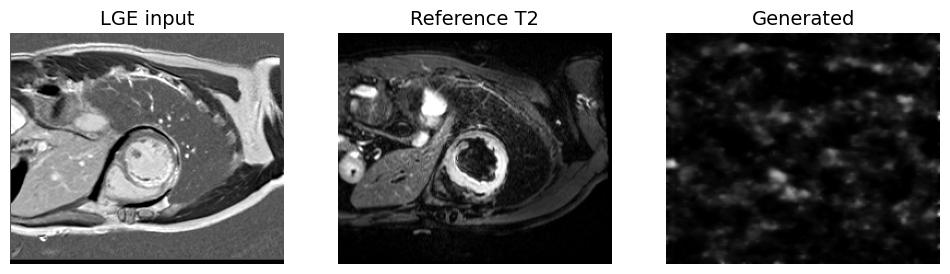

In [19]:
tf.random.set_seed(42)
example = next(record for record in VALID_PAIRS if record.target_modality == "T2")
lge_image, lge_volume, target_volume = load_aligned_pair(example)
slice_index = lge_volume.shape[2] // 2
lge_slice = tf.image.resize(
    lge_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
)
prediction = generate_conditioned(
    model, lge_slice[np.newaxis, ...], example.target_modality,
    alpha_cumprod, T, sampling_steps=100,
)[0, ..., 0]
prediction = tf.image.resize(
    prediction[..., np.newaxis], lge_volume.shape[:2]
)[..., 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(
    axes,
    (lge_volume[:, :, slice_index], target_volume[:, :, slice_index], prediction),
    ("LGE input", f"Reference {example.target_modality}", "Generated"),
):
    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [20]:
lge_only_root = DATA_ROOT / "Myo_train" / "MyoPS_train" / "CenterA"
lge_candidates = sorted(lge_only_root.rglob("*_LGE.nii.gz"))
if not lge_candidates:
    raise FileNotFoundError(f"No LGE volumes found under {lge_only_root}")
lge_path = lge_candidates[0]
case_id = lge_path.name.split("_")[0]
prediction_dir = Path("myo_predictions") / case_id
for target_modality in TARGET_MODALITIES:
    output_path = prediction_dir / f"{case_id}_{target_modality}_prediction.nii.gz"
    synthesize_volume(
        model, lge_path, target_modality, alpha_cumprod, T,
        image_size=IMAGE_SIZE, sampling_steps=100, output_path=output_path,
    )
    print(f"Saved normalized {target_modality} prediction to {output_path}")

Saved normalized C0 prediction to myo_predictions/Case1001/Case1001_C0_prediction.nii.gz
Saved normalized T2 prediction to myo_predictions/Case1001/Case1001_T2_prediction.nii.gz


The synthesized NIfTI volumes are stored in `myo_predictions/` on the canonical LGE voxel grid. Intensities are normalized to [-1, 1]; these are research image-synthesis outputs, not quantitative T2 maps or clinically validated predictions.